# Typology attribution of known laundering (HI-Small, HI-Medium)

IBM's `Patterns.txt` names the typology (FAN-OUT, CYCLE, STACK, …) for only part of the laundering transactions. This notebook estimates the typology of the rest:

1. **Group** laundering transactions that share accounts into candidate schemes (connected components of the laundering-only graph).
2. **Label** each group by its shape with simple rules (`classify`).
3. **Check** the rules against the schemes `Patterns.txt` already labels, before trusting them on the unlabelled part.

This is a **descriptive** analysis: it only looks at transactions already labelled laundering. It is not a detector and is kept separate from the Q1 detection results.

**Requirements:** `pip install duckdb pandas networkx matplotlib` (no Spark or Java needed).
**Inputs** (`data/` is git-ignored): `data/HI-<Small|Medium>_Trans.csv`, `data/HI-<Small|Medium>_Patterns.txt`, and `analysis/clean_transactions_duckdb.py`. Run top to bottom; the cleaning cells (§1, §11) only need to run once.

§1–§10 are HI-Small (where the rules were tuned). §11 runs the **same, unchanged** rules on HI-Medium as an out-of-sample check, and §12 compares the two.

In [ ]:
# !pip install duckdb pandas numpy networkx 

## 0. Setup

In [34]:
import duckdb
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

results = {}     # dataset -> summary numbers (filled in §9G, compared in §12)
crosstabs = {}   # dataset -> per-typology tables

## 1. Clean the raw transactions → curated Parquet

Uses `clean_transactions_duckdb.py`: parses every column as text, quarantines bad rows, drops exact duplicates and rows after the 10 Sep cut-off (the leaky tail), and adds `txn_id` and `week`. Output goes to `data/curated/` in the same layout as the AWS pipeline. Only needs to run once.

In [2]:
from clean_transactions_duckdb import clean

dq = clean(source="../data", output="../data/curated", dataset="HI-Small")
dq

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[clean] HI-Small: raw=5078345 quarantined=1108 duplicates_removed=9 clean=5077228  -> ../data/curated


,dataset,week,rows_raw,rows_quarantined,quarantine_by_reason,duplicates_removed,rows_clean,self_transfers,cross_currency,amount_mismatch,laundering_rows,min_time,max_time,run_at
0,HI-Small,1,2284182,0,{},2,2284180,531586.0,27649.0,0.0,1528.0,2022-09-01 00:00:00,2022-09-04 23:59:00,2026-10-26 10:47:25
1,HI-Small,2,2793451,396,"{""AFTER_CUTOFF"":396}",7,2793048,59233.0,44126.0,0.0,2994.0,2022-09-05 00:00:00,2022-09-10 23:59:00,2026-10-26 10:47:25
2,HI-Small,3,712,712,"{""AFTER_CUTOFF"":712}",0,0,0.0,0.0,0.0,0.0,NaN,NaN,2026-10-26 10:47:25


## 2. Load the laundering transactions

Laundering transactions only (`is_laundering = 1`), self-transfers excluded, from one dataset (the curated folder holds several). Accounts are keyed as `bank|account`.

> Uses the **whole** clean period. To restrict to an earlier period, pass `cutoff` (e.g. `"2022-09-07"`); see §9C for why that cuts many schemes short.

In [35]:
def load_laundering(dataset, cutoff=None):
    """Laundering txns of one dataset; with cutoff (e.g. "2022-09-11") only txns before it."""
    time_filter = f"AND t.txn_time < TIMESTAMP '{cutoff}'" if cutoff else ""
    L = duckdb.sql(f"""
      SELECT t.txn_id, t.txn_time AS ts,
             CAST(t.from_bank AS VARCHAR) || '|' || t.from_account AS src,
             CAST(t.to_bank   AS VARCHAR) || '|' || t.to_account   AS dst,
             CAST(t.amount_paid AS DOUBLE) AS amt_paid
      FROM read_parquet('../data/curated/transactions/**/*.parquet', hive_partitioning=true) t
      JOIN read_parquet('../data/curated/labels/**/*.parquet', hive_partitioning=true) l
        USING (txn_id, dataset)
      WHERE t.dataset = '{dataset}'
        AND l.is_laundering = 1
        AND NOT t.is_self_transfer
        {time_filter}
    """).df()
    L["ts"] = pd.to_datetime(L.ts).astype("datetime64[ns]")
    return L


DATASET = "HI-Small"
L = load_laundering(DATASET)
print(len(L), f"laundering txns, {DATASET}")

4514 laundering txns, HI-Small


## 3. Build the graph, group, and classify

Accounts are nodes and each payment is an edge. A **group** is a connected component (accounts linked by laundering payments, ignoring direction). `classify` labels each group by shape; checks run in this order:

| Order | Shape | Label |
|---|---|---|
| 1 | 1 transaction | SINGLE |
| 2 | one account receives from ≥2 and pays ≥2, and is in every payment | GATHER-SCATTER |
| 3 | contains a directed loop | CYCLE |
| 4 | only 2 accounts | PAIR |
| 5 | several unconnected pieces (only happens in the clean-scheme test, §9A) | STACK if any chain ≥2 hops, else BIPARTITE |
| 6 | 1 sender, everyone else only receives | FAN-OUT |
| 7 | 1 receiver, everyone else only sends | FAN-IN |
| 8 | 1 source → ≥2 middles → 1 sink, every middle paid by the source and paying the sink | SCATTER-GATHER |
| 9 | simple chain (every account ≤1 in, ≤1 out) | RANDOM |
| 10 | only senders and receivers, ≥2 of each | BIPARTITE |
| 11 | layered, ≥2 middle accounts, path ≥2 hops | STACK |
| 12 | anything else | OTHER |

Degrees count **distinct counterparties** (repeat payments between the same two accounts count once).

In [36]:
def classify(g):
    if g.number_of_edges() == 1:
        return "SINGLE"
    D = nx.DiGraph(g)                                   # distinct counterparties, repeats ignored
    ind, outd = dict(D.in_degree()), dict(D.out_degree())
    src = [v for v in D if ind[v] == 0]
    snk = [v for v in D if outd[v] == 0]
    mid = [v for v in D if ind[v] > 0 and outd[v] > 0]
    hubs = [v for v in D if ind[v] >= 2 and outd[v] >= 2]

    if len(hubs) == 1 and all(hubs[0] in e for e in D.edges()):
        return "GATHER-SCATTER"                         # before CYCLE: hub paying a sender back is still G-S
    if not nx.is_directed_acyclic_graph(D):
        return "CYCLE"                                  # before PAIR: A->B->A is a cycle
    if D.number_of_nodes() == 2:
        return "PAIR"
    if nx.number_weakly_connected_components(D) > 1:    # unconnected pieces (clean-scheme test only)
        return "STACK" if nx.dag_longest_path_length(D) >= 2 else "BIPARTITE"
    if len(src) == 1 and not mid:
        return "FAN-OUT"
    if len(snk) == 1 and not mid:
        return "FAN-IN"
    if (len(src) == 1 and len(snk) == 1 and len(mid) >= 2 and
            all(D.has_edge(src[0], v) and D.has_edge(v, snk[0]) for v in mid)):
        return "SCATTER-GATHER"
    if max(ind.values()) <= 1 and max(outd.values()) <= 1:
        return "RANDOM"                                 # a simple chain
    if not mid and len(src) >= 2 and len(snk) >= 2:
        return "BIPARTITE"
    if mid and nx.dag_longest_path_length(D) >= 2:
        return "STACK"
    return "OTHER"


def group_and_classify(L):
    """Graph of laundering payments, and one row per txn with its group and predicted label."""
    G = nx.MultiDiGraph()
    for r in L.itertuples():
        G.add_edge(r.src, r.dst, txn_id=r.txn_id, ts=r.ts)
    rows = []
    for gid, nodes in enumerate(nx.weakly_connected_components(G)):
        g = G.subgraph(nodes)
        t = classify(g)
        rows += [(d["txn_id"], gid, t) for _, _, d in g.edges(data=True)]
    return G, pd.DataFrame(rows, columns=["txn_id", "group_id", "typology_est"])


G, attr = group_and_classify(L)

## 4. Sanity check: group sizes and label counts

If one group held most transactions, separate schemes would be merging through shared accounts. Counts are **transactions**, not groups.

In [37]:
sizes = attr.groupby("group_id").size().sort_values(ascending=False)
print(len(sizes), "groups; largest 5:", sizes.head(5).tolist(), "of", len(attr), "txns")
attr.typology_est.value_counts()

1843 groups; largest 5: [247, 191, 98, 86, 67] of 4514 txns


typology_est
SINGLE            1439
STACK             1019
CYCLE              520
RANDOM             471
FAN-OUT            385
SCATTER-GATHER     270
FAN-IN             220
GATHER-SCATTER     152
PAIR                38
Name: count, dtype: int64

## 5. Parse `Patterns.txt` (the answer key)

Each `BEGIN LAUNDERING ATTEMPT - <TYPOLOGY>` … `END` block is one scheme. Keys are built the same way as in §2 (bank as a number, account in upper case) so rows can be matched.

In [38]:
def parse_patterns(path):
    prow, sid, typ = [], 0, None
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line.startswith("BEGIN LAUNDERING ATTEMPT"):
                sid += 1
                typ = line.split("-", 1)[1].split(":", 1)[0].strip().upper()
            elif line.startswith("END LAUNDERING ATTEMPT"):
                typ = None
            elif line and typ:
                p = line.split(",")
                prow.append((sid, typ, p[0], p[1], p[2], p[3], p[4], p[7]))

    P = pd.DataFrame(prow, columns=["scheme_id", "typology", "ts", "fb", "fa", "tb", "ta", "amt_paid"])
    P["ts"] = pd.to_datetime(P.ts, format="%Y/%m/%d %H:%M").astype("datetime64[ns]")
    P["src"] = P.fb.astype(int).astype(str) + "|" + P.fa.str.upper()
    P["dst"] = P.tb.astype(int).astype(str) + "|" + P.ta.str.upper()
    P["amt_paid"] = P.amt_paid.astype(float)
    return P[["scheme_id", "typology", "ts", "src", "dst", "amt_paid"]]


P = parse_patterns(f"../data/{DATASET}_Patterns.txt")
print(P.scheme_id.nunique(), "schemes in Patterns")

370 schemes in Patterns


## 6. Join: how much laundering has a known typology?

Matches each laundering transaction to `Patterns.txt` on time, accounts and amount.

In [39]:
V = (L.merge(P, on=["ts", "src", "dst", "amt_paid"], how="left")
      .merge(attr, on="txn_id"))
print(f"{V.scheme_id.notna().mean():.0%} of laundering txns have a known typology")

56% of laundering txns have a known typology


## 7. Validate on the real groups

For each group that contains known scheme transactions:

- **Purity:** does the group contain exactly one scheme?
- **Accuracy:** the group's true typology (most common among its known txns) vs. its predicted label.

Crosstab: rows = true typology, columns = predicted, cells = number of groups.

In [40]:
known = V[V.scheme_id.notna()]
purity = known.groupby("group_id").scheme_id.nunique()
print(f"{(purity == 1).mean():.0%} of groups contain exactly one scheme")

grp = known.groupby("group_id").agg(true=("typology", lambda s: s.mode()[0]),
                                    pred=("typology_est", "first"))
print(f"accuracy: {(grp.true == grp.pred).mean():.0%}")
pd.crosstab(grp.true, grp.pred)

95% of groups contain exactly one scheme
accuracy: 21%


pred,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,RANDOM,SCATTER-GATHER,SINGLE,STACK
true,,,,,,,,
BIPARTITE,0,1,1,0,3,0,194,0
CYCLE,32,0,0,0,7,0,2,0
FAN-IN,1,20,0,0,0,0,2,3
FAN-OUT,1,0,19,0,0,0,3,6
GATHER-SCATTER,1,10,0,8,0,0,2,9
RANDOM,2,0,0,0,18,0,4,0
SCATTER-GATHER,2,0,4,0,0,15,1,9
STACK,0,0,0,2,167,0,17,9


**Reading it:** grouping works (high purity), but accuracy is dragged down by BIPARTITE and STACK: each of those schemes is split into many small groups (§9D), and each piece looks like a single payment or a short chain. Excluding those two, accuracy is much higher. A STACK prediction is unreliable.

## 8. The finding: what is the unlabelled laundering like?

In [41]:
unknown = V[V.scheme_id.isna()]
print(len(unknown), "laundering txns without a known typology")
unknown.typology_est.value_counts(normalize=True).round(3)

1968 laundering txns without a known typology


typology_est
SINGLE            0.617
STACK             0.239
FAN-OUT           0.110
PAIR              0.019
RANDOM            0.008
CYCLE             0.006
GATHER-SCATTER    0.001
Name: proportion, dtype: float64

**Reading it:**

- Most unlabelled laundering is **isolated single payments** with no laundering neighbours. No structure-based rule can catch these, which puts a **ceiling on recall** for pattern detectors.
- Caution: known BIPARTITE pieces also come out as SINGLE (§7), so some of these may be fragments of coordinated schemes.
- The STACK share is **low-confidence**; FAN-OUT is the most trustworthy structured label here.

## 9. Diagnostics: why real-group accuracy is lower

### 9A. Rules on clean schemes

Classifies each `Patterns.txt` scheme using only its own transactions, so nothing else is mixed in. This tests the rules on their own.

In [42]:
def graph_of(df):
    g = nx.MultiDiGraph()
    for r in df.itertuples():
        g.add_edge(r.src, r.dst)
    return g

pure = (P.groupby("scheme_id")
         .apply(lambda d: pd.Series({"true": d.typology.iloc[0], "pred": classify(graph_of(d))}))
         .reset_index())
print(f"rule accuracy on clean schemes: {(pure.true == pure.pred).mean():.0%}")
pd.crosstab(pure.true, pure.pred)

rule accuracy on clean schemes: 78%


pred,BIPARTITE,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,RANDOM,SCATTER-GATHER,SINGLE,STACK
true,,,,,,,,,
BIPARTITE,31,0,0,0,0,0,0,18,0
CYCLE,0,54,0,0,0,0,0,0,0
FAN-IN,0,0,36,0,0,0,0,4,0
FAN-OUT,0,0,0,40,0,0,0,8,0
GATHER-SCATTER,0,8,0,0,43,0,0,0,0
RANDOM,0,0,0,0,0,28,0,13,0
SCATTER-GATHER,0,11,0,0,2,0,31,0,0
STACK,0,14,0,0,0,4,0,0,25


### 9B. Pollution by other laundering

In [43]:
mix = V.groupby("group_id").agg(n=("txn_id", "size"),
                                known_share=("scheme_id", lambda s: s.notna().mean()))
has_known = mix[mix.known_share > 0]
print(f"{(has_known.known_share < 1).sum()} of {len(has_known)} groups with a known scheme "
      f"also contain other laundering txns; median known share {has_known.known_share.median():.0%}")

28 of 575 groups with a known scheme also contain other laundering txns; median known share 100%


### 9C. Truncation at a warm-up cut-off (7 Sep)

If we restricted §2 to the warm-up period, schemes that continue past the cut-off would have incomplete shapes.

In [44]:
span = P.groupby("scheme_id").ts.agg(["min", "max"])
cut = pd.Timestamp("2022-09-07")
print((span["min"] < cut).sum(), "schemes start in warm-up;",
      ((span["min"] < cut) & (span["max"] >= cut)).sum(), "of them continue past the cut-off")

220 schemes start in warm-up; 96 of them continue past the cut-off


### 9D. Are schemes split across groups?

In [45]:
frag = known.groupby("scheme_id").group_id.nunique()
print(f"{(frag > 1).mean():.0%} of schemes are split across several groups")
known.merge(frag.rename("n_groups"), left_on="scheme_id", right_index=True) \
     .groupby("typology").n_groups.mean().round(2)

15% of schemes are split across several groups


typology
BIPARTITE         8.72
CYCLE             1.06
FAN-IN            1.00
FAN-OUT           1.00
GATHER-SCATTER    1.00
RANDOM            1.02
SCATTER-GATHER    1.00
STACK             9.21
Name: n_groups, dtype: float64

### 9E. Scheme size and duration per typology

Medians per typology (`hours` = first to last transaction). Inputs for the Q1 detector windows and thresholds.

In [46]:
def shape_stats(d):
    D = nx.DiGraph(graph_of(d))
    return pd.Series({"txns": len(d), "accounts": D.number_of_nodes(),
                      "pieces": nx.number_weakly_connected_components(D),
                      "hours": (d.ts.max() - d.ts.min()).total_seconds() / 3600})

S = P.groupby("scheme_id").apply(shape_stats).join(P.groupby("scheme_id").typology.first())
print((S.txns == 1).sum(), "schemes have only 1 transaction")
S.groupby("typology")[["txns", "accounts", "pieces", "hours"]].median()

43 schemes have only 1 transaction


,txns,accounts,pieces,hours
typology,,,,
BIPARTITE,4.0,8.0,4.0,24.333333
CYCLE,4.0,4.0,1.0,71.883333
FAN-IN,8.0,9.0,1.0,84.933333
FAN-OUT,7.0,8.0,1.0,76.658333
GATHER-SCATTER,14.0,15.0,1.0,150.816667
RANDOM,3.0,4.0,1.0,46.000000
SCATTER-GATHER,14.0,9.0,1.0,88.766667
STACK,10.0,15.0,5.0,73.316667


### 9F. Example errors

Prints the remaining clean-scheme mistakes (from §9A) by type and one example scheme each, with accounts renamed A, B, C.

In [47]:
wrong = pure[pure.true != pure.pred]
print(f"accuracy {1 - len(wrong) / len(pure):.0%}\n")
print(wrong.groupby(["true", "pred"]).size().sort_values(ascending=False).to_string())

for (t, p_), grp_w in wrong.groupby(["true", "pred"]):
    sid = grp_w.scheme_id.iloc[0]
    d = P[P.scheme_id == sid].sort_values("ts")
    accts = pd.unique(d[["src", "dst"]].values.ravel())
    name = {a: (chr(65 + i) if i < 26 else f"Z{i}") for i, a in enumerate(accts)}
    print(f"\n=== true {t} -> predicted {p_}   (scheme {sid}: {len(d)} txns, {len(accts)} accounts)")
    for r in d.head(15).itertuples():
        print(f"  {r.ts:%m-%d %H:%M}  {name[r.src]} -> {name[r.dst]}   {r.amt_paid:,.2f}")
    if len(d) > 15:
        print(f"  ... {len(d) - 15} more")

accuracy 78%

true            pred          
BIPARTITE       SINGLE            18
STACK           CYCLE             14
RANDOM          SINGLE            13
SCATTER-GATHER  CYCLE             11
FAN-OUT         SINGLE             8
GATHER-SCATTER  CYCLE              8
FAN-IN          SINGLE             4
STACK           RANDOM             4
SCATTER-GATHER  GATHER-SCATTER     2

=== true BIPARTITE -> predicted SINGLE   (scheme 23: 1 txns, 2 accounts)
  09-02 09:14  A -> B   16,200.03

=== true FAN-IN -> predicted SINGLE   (scheme 32: 1 txns, 2 accounts)
  09-01 15:06  A -> B   36,537.53

=== true FAN-OUT -> predicted SINGLE   (scheme 48: 1 txns, 2 accounts)
  09-02 03:04  A -> B   15,536.84

=== true GATHER-SCATTER -> predicted CYCLE   (scheme 35: 2 txns, 2 accounts)
  09-01 14:04  A -> A   14,998.24
  09-01 17:22  B -> A   5,313.33

=== true RANDOM -> predicted SINGLE   (scheme 88: 1 txns, 2 accounts)
  09-03 03:30  A -> B   17,826.05

=== true SCATTER-GATHER -> predicted CYCLE   (scheme

### 9G. Record the results

Saves this dataset's headline numbers into `results` / `crosstabs` for the comparison in §12. `clean_accuracy_multi_txn` leaves out one-transaction schemes, which no shape rule can label.

In [48]:
one_txn = P.groupby("scheme_id").size() == 1
multi = pure[~pure.scheme_id.map(one_txn)]

results[DATASET] = {
    "laundering_txns": len(L),
    "groups": attr.group_id.nunique(),
    "largest_group_share": attr.groupby("group_id").size().max() / len(attr),
    "known_typology_share": V.scheme_id.notna().mean(),
    "purity": (purity == 1).mean(),
    "group_accuracy": (grp.true == grp.pred).mean(),
    "schemes": len(pure),
    "clean_accuracy": (pure.true == pure.pred).mean(),
    "clean_accuracy_multi_txn": (multi.true == multi.pred).mean(),
}
crosstabs[DATASET] = {
    "per_typology": pure.assign(ok=pure.true == pure.pred).groupby("true").ok.mean(),
    "unknown_mix": unknown.typology_est.value_counts(normalize=True),
}
pd.Series(results[DATASET]).round(3)

laundering_txns             4514.000
groups                      1843.000
largest_group_share            0.055
known_typology_share           0.564
purity                         0.953
group_accuracy                 0.210
schemes                      370.000
clean_accuracy                 0.778
clean_accuracy_multi_txn       0.881
dtype: float64

## 10. Draw one group (for slides)

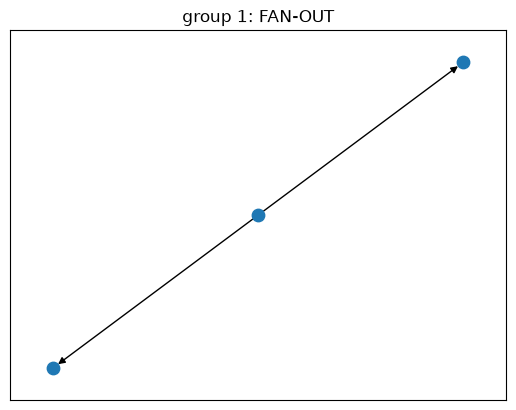

In [49]:
tx_group = attr.set_index("txn_id").group_id
typ = "FAN-OUT"                                          # change to explore other typologies
gid = attr[attr.typology_est == typ].group_id.iloc[0]
edges = [(u, v) for u, v, d in G.edges(data=True) if tx_group[d["txn_id"]] == gid]
nx.draw_networkx(nx.DiGraph(edges), with_labels=False, node_size=80, arrows=True)
plt.title(f"group {gid}: {typ}")
plt.show()

## Caveats

- **Clean-scheme accuracy is in-sample.** The rules were improved by looking at errors in these same schemes; §11 gives the honest score: the unchanged rules run on HI-Medium's `Patterns.txt`.
- **Accuracy counts every scheme or group equally,** regardless of size. Per-typology rates are more informative.
- **Self-transfers are excluded in §2,** but `Patterns.txt` schemes include self-payments, so a few scheme transactions are missing from the graph.
- **This is not detection.** It must not be used to tune or report Q1 detector results on the test period.

## 11. HI-Medium (out-of-sample check)

Same steps as §2–§9 on HI-Medium, using the functions and `classify` defined above. **Do not edit `classify` before running this**: the point is to test the rules as tuned on HI-Small.

- HI-Medium's normal data runs to **16 Sep** (Small's ends on 10 Sep), so it is cleaned with that cut-off; the sparse, laundering-heavy tail from 17 Sep is dropped, as for Small.
- These cells overwrite `L`, `G`, `attr`, `P`, `V`, … — after running them, don't re-run the §2–§10 cells without re-running from §2.
- §9C (7 Sep warm-up cut) is skipped; set `CUTOFF = "2022-09-11"` below to see the effect of cutting Medium at Small's period instead.

In [ ]:
dq_medium = clean(source="../data", output="../data/curated", dataset="HI-Medium",
                  max_timestamp="2022-09-16 23:59")
dq_medium

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 11.1 Load, group, classify, and check group sizes (§2–§4)

If the largest group holds a big share of the transactions, schemes are merging through shared accounts and everything below will look worse.

In [50]:
DATASET = "HI-Medium"
CUTOFF = None          # or "2022-09-11" to match Small's period

L = load_laundering(DATASET, CUTOFF)
print(len(L), f"laundering txns, {DATASET}, cutoff={CUTOFF}")
G, attr = group_and_classify(L)

sizes = attr.groupby("group_id").size().sort_values(ascending=False)
print(len(sizes), "groups; largest 5:", sizes.head(5).tolist(), "of", len(attr), "txns")
attr.typology_est.value_counts()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

31086 laundering txns, HI-Medium, cutoff=None
11578 groups; largest 5: [4371, 334, 313, 295, 196] of 31086 txns


typology_est
SINGLE            8919
CYCLE             8881
STACK             5255
RANDOM            3406
FAN-OUT           1179
FAN-IN            1086
SCATTER-GATHER     870
GATHER-SCATTER     597
BIPARTITE          585
PAIR               308
Name: count, dtype: int64

### 11.2 Answer key and join (§5–§6)

In [51]:
P = parse_patterns(f"../data/{DATASET}_Patterns.txt")
print(P.scheme_id.nunique(), "schemes in Patterns")

V = (L.merge(P, on=["ts", "src", "dst", "amt_paid"], how="left")
      .merge(attr, on="txn_id"))
print(f"{V.scheme_id.notna().mean():.0%} of laundering txns have a known typology")

2756 schemes in Patterns
60% of laundering txns have a known typology


### 11.3 Validate on the real groups (§7)

In [52]:
known = V[V.scheme_id.notna()]
purity = known.groupby("group_id").scheme_id.nunique()
print(f"{(purity == 1).mean():.0%} of groups contain exactly one scheme")

grp = known.groupby("group_id").agg(true=("typology", lambda s: s.mode()[0]),
                                    pred=("typology_est", "first"))
print(f"accuracy: {(grp.true == grp.pred).mean():.0%}")
pd.crosstab(grp.true, grp.pred)

93% of groups contain exactly one scheme
accuracy: 17%


pred,BIPARTITE,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,RANDOM,SCATTER-GATHER,SINGLE,STACK
true,,,,,,,,,
BIPARTITE,1,2,16,11,0,32,0,1470,1
CYCLE,0,150,0,0,0,43,0,18,6
FAN-IN,5,7,127,0,0,0,0,7,37
FAN-OUT,5,4,0,112,0,0,0,9,34
GATHER-SCATTER,4,15,42,0,39,0,0,12,54
RANDOM,0,4,0,1,0,124,0,25,27
SCATTER-GATHER,1,19,0,15,0,0,62,9,65
STACK,0,9,1,3,4,1139,0,224,61


### 11.4 Unlabelled laundering (§8)

In [53]:
unknown = V[V.scheme_id.isna()]
print(len(unknown), "laundering txns without a known typology")
unknown.typology_est.value_counts(normalize=True).round(3)

12487 laundering txns without a known typology


typology_est
SINGLE            0.572
CYCLE             0.226
STACK             0.096
BIPARTITE         0.035
FAN-OUT           0.028
PAIR              0.025
RANDOM            0.016
FAN-IN            0.001
GATHER-SCATTER    0.000
Name: proportion, dtype: float64

### 11.5 Rules on clean schemes (§9A)

In [54]:
pure = (P.groupby("scheme_id")
         .apply(lambda d: pd.Series({"true": d.typology.iloc[0], "pred": classify(graph_of(d))}))
         .reset_index())
print(f"rule accuracy on clean schemes: {(pure.true == pure.pred).mean():.0%}")
pd.crosstab(pure.true, pure.pred)

rule accuracy on clean schemes: 76%


pred,BIPARTITE,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,RANDOM,SCATTER-GATHER,SINGLE,STACK
true,,,,,,,,,
BIPARTITE,243,0,0,0,0,0,0,126,0
CYCLE,0,367,0,0,0,0,0,0,0
FAN-IN,0,0,291,0,0,0,0,64,0
FAN-OUT,1,0,0,261,0,0,0,83,0
GATHER-SCATTER,0,65,0,0,256,0,0,0,1
RANDOM,0,0,0,0,0,240,0,91,0
SCATTER-GATHER,0,74,0,0,37,0,220,0,0
STACK,0,89,0,0,0,26,0,0,221


### 11.6 Pollution, fragmentation, scheme shapes (§9B, §9D, §9E)

In [55]:
mix = V.groupby("group_id").agg(n=("txn_id", "size"),
                                known_share=("scheme_id", lambda s: s.notna().mean()))
has_known = mix[mix.known_share > 0]
print(f"{(has_known.known_share < 1).sum()} of {len(has_known)} groups with a known scheme "
      f"also contain other laundering txns; median known share {has_known.known_share.median():.0%}")

266 of 4056 groups with a known scheme also contain other laundering txns; median known share 100%


In [56]:
frag = known.groupby("scheme_id").group_id.nunique()
print(f"{(frag > 1).mean():.0%} of schemes are split across several groups")
known.merge(frag.rename("n_groups"), left_on="scheme_id", right_index=True) \
     .groupby("typology").n_groups.mean().round(2)

15% of schemes are split across several groups


typology
BIPARTITE         9.23
CYCLE             1.02
FAN-IN            1.00
FAN-OUT           1.01
GATHER-SCATTER    1.01
RANDOM            1.02
SCATTER-GATHER    1.00
STACK             9.11
Name: n_groups, dtype: float64

In [57]:
def shape_stats(d):
    D = nx.DiGraph(graph_of(d))
    return pd.Series({"txns": len(d), "accounts": D.number_of_nodes(),
                      "pieces": nx.number_weakly_connected_components(D),
                      "hours": (d.ts.max() - d.ts.min()).total_seconds() / 3600})

S = P.groupby("scheme_id").apply(shape_stats).join(P.groupby("scheme_id").typology.first())
print((S.txns == 1).sum(), "schemes have only 1 transaction")
S.groupby("typology")[["txns", "accounts", "pieces", "hours"]].median()

364 schemes have only 1 transaction


,txns,accounts,pieces,hours
typology,,,,
BIPARTITE,4.0,8.0,4.0,42.550000
CYCLE,5.0,5.0,1.0,121.816667
FAN-IN,6.0,7.0,1.0,119.166667
FAN-OUT,5.0,6.0,1.0,115.550000
GATHER-SCATTER,14.0,14.5,1.0,227.358333
RANDOM,4.0,5.0,1.0,93.500000
SCATTER-GATHER,8.0,6.0,1.0,131.416667
STACK,10.0,12.0,4.0,102.558333


### 11.7 Example errors (§9F)

Check whether these are the same unavoidable kinds as on Small (one-transaction schemes, two-account A↔B schemes) or new ones.

In [58]:
wrong = pure[pure.true != pure.pred]
print(f"accuracy {1 - len(wrong) / len(pure):.0%}\n")
print(wrong.groupby(["true", "pred"]).size().sort_values(ascending=False).to_string())

for (t, p_), grp_w in wrong.groupby(["true", "pred"]):
    sid = grp_w.scheme_id.iloc[0]
    d = P[P.scheme_id == sid].sort_values("ts")
    accts = pd.unique(d[["src", "dst"]].values.ravel())
    name = {a: (chr(65 + i) if i < 26 else f"Z{i}") for i, a in enumerate(accts)}
    print(f"\n=== true {t} -> predicted {p_}   (scheme {sid}: {len(d)} txns, {len(accts)} accounts)")
    for r in d.head(15).itertuples():
        print(f"  {r.ts:%m-%d %H:%M}  {name[r.src]} -> {name[r.dst]}   {r.amt_paid:,.2f}")
    if len(d) > 15:
        print(f"  ... {len(d) - 15} more")

accuracy 76%

true            pred          
BIPARTITE       SINGLE            126
RANDOM          SINGLE             91
STACK           CYCLE              89
FAN-OUT         SINGLE             83
SCATTER-GATHER  CYCLE              74
GATHER-SCATTER  CYCLE              65
FAN-IN          SINGLE             64
SCATTER-GATHER  GATHER-SCATTER     37
STACK           RANDOM             26
FAN-OUT         BIPARTITE           1
GATHER-SCATTER  STACK               1

=== true BIPARTITE -> predicted SINGLE   (scheme 27: 1 txns, 2 accounts)
  09-02 14:43  A -> B   522.58

=== true FAN-IN -> predicted SINGLE   (scheme 60: 1 txns, 2 accounts)
  09-01 07:29  A -> B   8,922.77

=== true FAN-OUT -> predicted BIPARTITE   (scheme 1893: 12 txns, 14 accounts)
  09-12 02:44  A -> B   8,521.67
  09-12 05:57  A -> C   9,742.59
  09-12 17:41  D -> E   1.11
  09-13 02:28  A -> F   9,193.80
  09-13 08:06  A -> G   1,939,928.05
  09-13 09:04  A -> H   59,237.79
  09-13 22:53  A -> I   986.92
  09-14 12:07  A ->

### 11.8 Record the results (§9G)

In [59]:
one_txn = P.groupby("scheme_id").size() == 1
multi = pure[~pure.scheme_id.map(one_txn)]

results[DATASET] = {
    "laundering_txns": len(L),
    "groups": attr.group_id.nunique(),
    "largest_group_share": attr.groupby("group_id").size().max() / len(attr),
    "known_typology_share": V.scheme_id.notna().mean(),
    "purity": (purity == 1).mean(),
    "group_accuracy": (grp.true == grp.pred).mean(),
    "schemes": len(pure),
    "clean_accuracy": (pure.true == pure.pred).mean(),
    "clean_accuracy_multi_txn": (multi.true == multi.pred).mean(),
}
crosstabs[DATASET] = {
    "per_typology": pure.assign(ok=pure.true == pure.pred).groupby("true").ok.mean(),
    "unknown_mix": unknown.typology_est.value_counts(normalize=True),
}
pd.Series(results[DATASET]).round(3)

laundering_txns             31086.000
groups                      11578.000
largest_group_share             0.141
known_typology_share            0.598
purity                          0.925
group_accuracy                  0.167
schemes                      2756.000
clean_accuracy                  0.762
clean_accuracy_multi_txn        0.878
dtype: float64

## 12. HI-Small vs HI-Medium

Needs §9G and §11.8 run in the same kernel session. HI-Small's clean-scheme accuracy is in-sample (the rules were tuned on it); HI-Medium's is out-of-sample.

In [60]:
pd.DataFrame(results).round(3)

,HI-Small,HI-Medium
laundering_txns,4514.000,31086.000
groups,1843.000,11578.000
largest_group_share,0.055,0.141
known_typology_share,0.564,0.598
purity,0.953,0.925
group_accuracy,0.210,0.167
schemes,370.000,2756.000
clean_accuracy,0.778,0.762
clean_accuracy_multi_txn,0.881,0.878


In [61]:
pd.DataFrame({k: v["per_typology"] for k, v in crosstabs.items()}).round(2)     # clean-scheme accuracy per typology

,HI-Small,HI-Medium
true,,
BIPARTITE,0.63,0.66
CYCLE,1.00,1.00
FAN-IN,0.90,0.82
FAN-OUT,0.83,0.76
GATHER-SCATTER,0.84,0.80
RANDOM,0.68,0.73
SCATTER-GATHER,0.70,0.66
STACK,0.58,0.66


In [62]:
pd.DataFrame({k: v["unknown_mix"] for k, v in crosstabs.items()}).round(3)      # predicted mix of unlabelled laundering

,HI-Small,HI-Medium
typology_est,,
BIPARTITE,NaN,0.035
CYCLE,0.006,0.226
FAN-IN,NaN,0.001
FAN-OUT,0.110,0.028
GATHER-SCATTER,0.001,0.000
PAIR,0.019,0.025
RANDOM,0.008,0.016
SINGLE,0.617,0.572
STACK,0.239,0.096


## 13. Stage 2 grouping: how long should accounts stay linked across days?

The pipeline's stage 2 (`pipeline/group_stage2.py`) names patterns from **groups of account-days**, not from the transaction graph used above:

- **node** = an account on one day; **edge** = any payment between two nodes on the same day
- the same account on two days is linked only if the days are ≤ `LINK_DAYS` (2) apart **and** the account has ≤ `MAX_LINKED_DAYS` (3) suspicious days
- accounts with > `HUB_DEGREE` (30) counterparties never join a group

§9E shows schemes typically run 2–9 days, so a 3-day limit may cut schemes into pieces before the namer sees them. This section rebuilds the pipeline's groups from **all true laundering** of each dataset (an upper bound: no stage 1 misses or false alerts) and sweeps the two cross-day settings.

- **purity:** share of groups (with a known scheme) that contain exactly one scheme
- **schemes_whole:** share of schemes that land in a single group
- **groups_per_scheme / scheme_share_in_main_group:** how badly the rest are split

Uses `load_laundering` and `parse_patterns` from §2 and §5. The sweep takes ~2–3 minutes.

In [63]:
from collections import defaultdict

HUB_DEGREE = 30                  # group_stage2.py: accounts with more counterparties don't join groups
LINK_GRID = [2, 3, 5]            # LINK_DAYS: same account on days this close = same group (pipeline: 2)
LINKED_GRID = [3, 5, 10, 20]        # MAX_LINKED_DAYS: only accounts with this few days are linked (pipeline: 3)


def stage2_inputs(dataset):
    """Stage 2's nodes and edges, built from ALL true laundering instead of stage 1's alerts.
    nodes  = account-days with a laundering payment (sent or received)
    edges  = any payment between two nodes on the same day (as scheme_stage2.read_payments)
    member = which scheme(s) each node belongs to, from Patterns.txt"""
    L = load_laundering(dataset)
    P = parse_patterns(f"../data/{dataset}_Patterns.txt")
    T = L.merge(P, on=["ts", "src", "dst", "amt_paid"], how="left")
    T["date"] = T.ts.dt.normalize()
    ends = pd.concat([T[["src", "date", "scheme_id", "typology"]].rename(columns={"src": "k"}),
                      T[["dst", "date", "scheme_id", "typology"]].rename(columns={"dst": "k"})])
    nodes = ends[["k", "date"]].drop_duplicates()
    member = ends.dropna(subset=["scheme_id"]).drop_duplicates()

    con = duckdb.connect()
    con.register("nodes", nodes)
    edges = con.sql(f"""
      WITH t AS (
        SELECT txn_date,
               CAST(from_bank AS VARCHAR) || '|' || from_account AS src,
               CAST(to_bank   AS VARCHAR) || '|' || to_account   AS dst
        FROM read_parquet('../data/curated/transactions/**/*.parquet', hive_partitioning=true)
        WHERE dataset = '{dataset}')
      SELECT t.src, t.dst, CAST(t.txn_date AS TIMESTAMP) AS date FROM t
      JOIN nodes a ON a.k = t.src AND CAST(a.date AS DATE) = t.txn_date
      JOIN nodes b ON b.k = t.dst AND CAST(b.date AS DATE) = t.txn_date
      WHERE t.src <> t.dst
    """).df()
    edges["date"] = pd.to_datetime(edges.date).astype("datetime64[ns]")
    return nodes, edges, member


def link_groups(nodes, edges, link_days, max_linked, hub_degree=HUB_DEGREE):
    """group_stage2.build_groups, with the two cross-day settings as arguments."""
    node_set = set(zip(nodes.k, nodes.date))
    deg = defaultdict(set)
    for s, t in zip(edges.src, edges.dst):
        deg[s].add(t); deg[t].add(s)
    hub = {a for a, cp in deg.items() if len(cp) > hub_degree}
    uf = nx.utils.UnionFind(node_set)
    for s, t, d in zip(edges.src, edges.dst, edges.date):
        if s not in hub and t not in hub:
            uf.union((s, d), (t, d))
    by_acct = defaultdict(list)
    for k, d in node_set:
        by_acct[k].append(d)
    for k, days in by_acct.items():
        if k in hub or len(days) > max_linked:
            continue
        days.sort()
        for a, b in zip(days, days[1:]):
            if (b - a).days <= link_days:
                uf.union((k, a), (k, b))
    return {n: i for i, s in enumerate(uf.to_sets()) for n in s}


def grouping_stats(gid, member):
    """How well the groups match the schemes. Returns the summary and one row per scheme."""
    m = member.assign(g=[gid[n] for n in zip(member.k, member.date)])
    size = pd.Series(list(gid.values())).value_counts()
    per_scheme = m.groupby("scheme_id").agg(
        typology=("typology", "first"), n_groups=("g", "nunique"),
        main_share=("g", lambda g: g.value_counts().iloc[0] / len(g)))
    return {"groups": len(size),
            "largest_group_share": size.max() / len(gid),
            "purity": (m.groupby("g").scheme_id.nunique() == 1).mean(),
            "schemes_whole": (per_scheme.n_groups == 1).mean(),
            "groups_per_scheme": per_scheme.n_groups.mean(),
            "scheme_share_in_main_group": per_scheme.main_share.mean()}, per_scheme

In [64]:
sweep, frag = [], {}
for ds_name in ["HI-Small", "HI-Medium"]:
    nodes, edges, member = stage2_inputs(ds_name)
    print(f"{ds_name}: {len(nodes)} laundering account-days, {len(edges)} linking payments")
    for link_days in LINK_GRID:
        for max_linked in LINKED_GRID:
            stats, per_scheme = grouping_stats(link_groups(nodes, edges, link_days, max_linked), member)
            sweep.append({"dataset": ds_name, "link_days": link_days, "max_linked_days": max_linked, **stats})
            frag[(ds_name, link_days, max_linked)] = per_scheme.groupby("typology").n_groups.mean()
sweep = pd.DataFrame(sweep).set_index(["dataset", "link_days", "max_linked_days"])
sweep.round(3)

HI-Small: 7130 laundering account-days, 6367 linking payments


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

HI-Medium: 49665 laundering account-days, 44356 linking payments


groups  largest_group_share  purity  \
dataset   link_days max_linked_days                                        
HI-Small  2         3                  2723                0.016   0.930   
                    5                  2584                0.017   0.919   
                    10                 2429                0.029   0.954   
                    20                 2429                0.029   0.954   
          3         3                  2665                0.020   0.921   
                    5                  2527                0.020   0.911   
                    10                 2372                0.029   0.945   
                    20                 2372                0.029   0.945   
          5         3                  2637                0.021   0.919   
                    5                  2498                0.022   0.912   
                    10                 2346                0.029   0.942   
                    20                 2346                0.029   0.942   
HI-Medium 2         3                 20552                0.002   0.913   
                    5                 19488                0.005   0.905   
                    10                17875                0.013   0.910   
                    20                17407                0.017   0.951   
          3         3                 19742                0.003   0.902   
                    5                 18819                0.006   0.895   
                    10                17184                0.022   0.897   
                    20                16720                0.029   0.943   
          5         3                 19235                0.004   0.892   
                    5                 18358                0.021   0.886   
                    10                16726                0.039   0.889   
                    20                16268                0.050   0.937   

                                     schemes_whole  groups_per_scheme  \
dataset   link_days max_linked_days                                     
HI-Small  2         3                        0.545              2.829   
                    5                        0.661              2.460   
                    10                       0.815              2.107   
                    20                       0.815              2.107   
          3         3                        0.579              2.722   
                    5                        0.694              2.355   
                    10                       0.848              2.006   
                    20                       0.848              2.006   
          5         3                        0.587              2.705   
                    5                        0.708              2.333   
                    10                       0.854              1.997   
                    20                       0.854              1.997   
HI-Medium 2         3                        0.408              3.594   
                    5                        0.507              3.211   
                    10                       0.652              2.540   
                    20                       0.761              2.351   
          3         3                        0.452              3.344   
                    5                        0.558              3.018   
                    10                       0.712              2.341   
                    20                       0.821              2.154   
          5         3                        0.487              3.233   
                    5                        0.584              2.927   
                    10                       0.740              2.249   
                    20                       0.848              2.062   

                                     scheme_share_in_main_group  
dataset   link_days max_linked_days                              
HI-Small  2         3        

Groups per scheme by typology: the pipeline's setting (2/3) vs longer linking (`link_days/max_linked_days`).

In [65]:
pd.DataFrame({f"{d} {l}/{m}": frag[(d, l, m)]
              for d in ["HI-Small", "HI-Medium"] for l, m in [(2, 3), (2, 10), (2, 20)]}).round(2)

,HI-Small 2/3,HI-Small 2/10,HI-Small 2/20,HI-Medium 2/3,HI-Medium 2/10,HI-Medium 2/20
typology,,,,,,
BIPARTITE,5.13,5.04,5.04,5.49,5.35,5.33
CYCLE,1.43,1.20,1.20,1.72,1.47,1.26
FAN-IN,2.38,1.00,1.00,2.97,1.16,1.07
FAN-OUT,2.27,1.04,1.04,2.96,1.17,1.07
GATHER-SCATTER,3.06,1.02,1.02,4.31,1.63,1.12
RANDOM,1.07,1.02,1.02,1.40,1.21,1.14
SCATTER-GATHER,1.36,1.02,1.02,2.85,1.47,1.16
STACK,6.38,6.10,6.10,7.36,7.09,6.86


**Reading it:**

- **`MAX_LINKED_DAYS` is the setting that matters; `LINK_DAYS` barely does.** At `LINK_DAYS = 2`, raising `MAX_LINKED_DAYS` from 3 to 20 on HI-Medium takes schemes kept whole from **41% → 76%** and groups per scheme from 3.6 → 2.4, while purity *rises* (91% → 95%) and the largest group stays under 2% of account-days. Small: 55% → 82% whole at 10 (Small spans 10 days, so 10 and 20 are identical).
- **Why:** the hub of a fan or gather-scatter is active on many days. A 3-day limit drops exactly those accounts from cross-day linking, so FAN-IN / FAN-OUT / GATHER-SCATTER break into 3–4 groups on Medium; with longer linking they become ~1.1.
- **Longer `LINK_DAYS` (3, 5) makes a few more schemes whole but lowers purity and grows the largest group**, so 2 is fine.
- **BIPARTITE and STACK stay at 5–7 groups per scheme whatever the setting**: their pieces share no accounts, so no linking rule joins them (consistent with §9D and the pipeline's "layering" merge).

**Suggested change for the team:** keep `LINK_DAYS = 2`, raise `MAX_LINKED_DAYS` to 10–20, and re-run `group_stage2.py` on the validation alerts (the namer must be retrained, since its group features change). Check the largest group there: this test has no false alerts, and keeping busy, repeatedly flagged normal accounts apart is what the 3-day limit was for. The datasets span ≤ 16 days, so 20 here means "no limit"; on HI-Large's window, a cap still guards against long chains.

## 14. Local preview of round 4: does longer linking help a shape-based namer?

Round 4 (`experiments/round4_grouping.sh`) grades the stage 2 namers on the pipeline's real validation alerts, which needs EMR. This is the same question on §13's groups of **all true laundering**:

- every laundering account-day is named by `classify` on the payments inside its group (`pipeline/shape_rules.py` does the same on EMR); a group with no payment inside is "unclassified"
- truth = the pipeline's own account-day label (`build_features_spark.py`): the pattern of the earliest scheme payment that day, "unclassified" if none; bipartite + stack = layering
- F1 per class and macro F1 over the 7 patterns, as `group_stage2.class_table`

**An upper bound, not comparable to the pipeline's 0.474:** no stage 1 misses and no false alerts. Compare the settings with each other. Self-transfers are excluded here (§2). Takes ~2–3 minutes.

In [66]:
MERGE = {"BIPARTITE": "layering", "STACK": "layering"}      # the pipeline's 7 classes
TO_CLASS = {"FAN-IN": "fan_in", "FAN-OUT": "fan_out", "GATHER-SCATTER": "gather_scatter",
            "SCATTER-GATHER": "scatter_gather", "CYCLE": "cycle", "RANDOM": "random", **MERGE}
CLASSES = ["fan_in", "fan_out", "gather_scatter", "scatter_gather", "cycle", "random", "layering"]


def node_truth(nodes, dataset):
    """Stage 2's label per laundering account-day (build_features_spark.py): the pattern of its
    earliest scheme payment that day; "unclassified" if none of its laundering is in a scheme."""
    T = load_laundering(dataset).merge(parse_patterns(f"../data/{dataset}_Patterns.txt"),
                                       on=["ts", "src", "dst", "amt_paid"])
    T["date"], T["cls"] = T.ts.dt.normalize(), T.typology.map(TO_CLASS)
    ends = pd.concat([T[["src", "date", "ts", "cls"]].rename(columns={"src": "k"}),
                      T[["dst", "date", "ts", "cls"]].rename(columns={"dst": "k"})])
    first = ends.sort_values("ts").drop_duplicates(["k", "date"])
    return nodes.merge(first[["k", "date", "cls"]], how="left").cls.fillna("unclassified").to_numpy()


def rule_names(nodes, edges, gid):
    """shape_rules.py on each group: classify the payments inside it (none -> unclassified)."""
    inside = edges[[gid[(s, d)] == gid[(t, d)] for s, t, d in zip(edges.src, edges.dst, edges.date)]]
    g_of = [gid[(s, d)] for s, d in zip(inside.src, inside.date)]
    names = {g: TO_CLASS.get(classify(nx.MultiDiGraph(list(zip(e.src, e.dst)))), "unclassified")
             for g, e in inside.assign(g=g_of).groupby("g")}
    return np.array([names.get(gid[n], "unclassified") for n in zip(nodes.k, nodes.date)])


def class_table(true, pred):
    """Per class as group_stage2.class_table: true cases, named as, correct, precision, recall,
    F1, plus the macro over the 7 patterns (unclassified is shown but not in the macro)."""
    rows = {}
    for c in CLASSES + ["unclassified"]:
        tp, n_pred, n_true = ((true == c) & (pred == c)).sum(), (pred == c).sum(), (true == c).sum()
        p, r = (tp / n_pred if n_pred else 0.0), (tp / n_true if n_true else 0.0)
        rows[c] = {"true_cases": n_true, "named_as": n_pred, "correct": tp, "label_precision": p,
                   "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0}
    t = pd.DataFrame(rows).T
    pat = t.loc[CLASSES]
    t.loc["MACRO (7 patterns)"] = [pat.true_cases.sum(), pat.named_as.sum(), pat.correct.sum(),
                                   pat.label_precision.mean(), pat.recall.mean(), pat.f1.mean()]
    return t.astype({"true_cases": int, "named_as": int, "correct": int})

In [70]:
rules_tables = {}                       # (dataset, max_linked) -> full per-class table
for ds_name in ["HI-Small", "HI-Medium"]:
    nodes, edges, _ = stage2_inputs(ds_name)
    true = node_truth(nodes, ds_name)
    for max_linked in [3, 10, 20]:
        pred = rule_names(nodes, edges, link_groups(nodes, edges, 2, max_linked))
        rules_tables[(ds_name, max_linked)] = class_table(true, pred)
rules_f1 = pd.DataFrame({f"{d} 2/{m}": t.f1 for (d, m), t in rules_tables.items()})
rules_f1.round(3)

NameError: name 'class_table' is not defined

**Reading it:**

- **Longer linking helps the shape-based namer a lot:** macro F1 over the 7 patterns goes **0.31 → 0.43** on HI-Medium and **0.42 → 0.50** on HI-Small when `MAX_LINKED_DAYS` goes from 3 to 20 (10 gets most of it). The gain is where §13 predicted: gather-scatter (Medium 0.09 → 0.47) and scatter-gather (0.06 → 0.43), whose hub accounts were being cut out of cross-day links, plus fan-in / fan-out.
- **Cycle drops a little (0.52 → 0.43):** bigger groups pull in extra payments that break the clean loop shape.
- **The rules cannot name layering (F1 ≈ 0.07 at every setting):** layering schemes arrive as unconnected pieces that look like single payments or chains. The pipeline's trained namer reached 0.642 on layering in round 3, so the model adds most of its value there; a rules-only namer is not an alternative.
- **What round 4 on EMR should confirm:** that the trained group namer gains from `MAX_LINKED_DAYS` 10–20 on real alerts too, without false alerts merging into large groups.

In [69]:
# Write the preview in the layout of results/experiments/round3_*.txt: one block per setting,
# then the summary. Columns match round 3's stage 2 table, but every number here is on ALL true
# laundering (round 3's "oracle" view): no stage 1 misses or false alerts, so there is no e2e / caught.
lines = ["§14 local preview: rules namer (shape_rules.py) on ALL true laundering of HI-Small / HI-Medium",
         "upper bound: like round 3's oracle_f1, not comparable to end-to-end numbers", ""]
for m in [3, 10, 20]:
    lines.append(f"=================== rules namer · LINK_DAYS=2 MAX_LINKED_DAYS={m}")
    for d in ["HI-Medium", "HI-Small"]:
        lines += [f"-- {d}", rules_tables[(d, m)].round(3).to_string()]
    lines.append("")
lines += ["=================== SUMMARY · rules namer F1 per pattern, columns = dataset LINK_DAYS/MAX_LINKED_DAYS",
          rules_f1.round(3).to_string()]
with open("../results/experiments/round4_local_preview.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

NameError: name 'rules_tables' is not defined